In [1]:
from rdkit import Chem 
from rdkit.Chem import AllChem
from rdkit.Chem import Draw
import py3Dmol
import numpy as np

from pyscf import gto, scf
from pyscf.geomopt.geometric_solver import optimize
from pyscf.data.nist import *


from pyscf.prop.freq.rhf import Freq #Как на семинаре не получилось, модуля Infrared у меня не видит и pip install тоже 
from pyscf.hessian import thermo
import matplotlib.pyplot as plt

/home/ayre/jupyter-new/lib/python3.14/site-packages/pyscf/prop/efg/rhf.py:45: UserWarning: Module EFG is under testing
  warnings.warn('Module EFG is under testing')
/home/ayre/jupyter-new/lib/python3.14/site-packages/pyscf/prop/efg/dhf.py:30: UserWarning: Module EFG is under testing
  warnings.warn('Module EFG is under testing')
/home/ayre/jupyter-new/lib/python3.14/site-packages/pyscf/prop/zfs/uhf.py:40: UserWarning: Module ZFS is under testing
  warnings.warn('Module ZFS is under testing')
/home/ayre/jupyter-new/lib/python3.14/site-packages/pyscf/prop/gtensor/uhf.py:43: UserWarning: Module g-tensor is under testing
  warnings.warn('Module g-tensor is under testing')
/home/ayre/jupyter-new/lib/python3.14/site-packages/pyscf/prop/gtensor/uks.py:41: UserWarning: Module g-tensor is under testing
  warnings.warn('Module g-tensor is under testing')
/home/ayre/jupyter-new/lib/python3.14/site-packages/pyscf/prop/hfc/uks.py:35: UserWarning: Module HFC is under testing
  warnings.warn('Module

Задание 1

In [2]:

molecules = {
    'Бензол': 'c1ccccc1',
    'Фенол':  'c1cc(O)ccc1',
    'Анизол': 'c1cc(OC)ccc1'
}

def show(mol):
    v = py3Dmol.view(width=400, height=300)
    v.addModel(Chem.MolToMolBlock(mol), 'mol')
    v.setStyle({'stick': {}, 'sphere': {'scale': 0.25}})
    v.zoomTo()
    v.show()

def print_bonds(mol, dist_mat, label): #Получение длин связей через матрицу, можно получать через GetBondLength, но для этого нужно еще GetConformers
    print(f"\n{label}")
    for bond in mol.GetBonds():
        i = bond.GetBeginAtomIdx() #
        j = bond.GetEndAtomIdx()
        s1 = mol.GetAtomWithIdx(i).GetSymbol()
        s2 = mol.GetAtomWithIdx(j).GetSymbol()

        L = dist_mat[i][j]       
        if s1 == 'C' and s2 == 'C':
            print(f"  C–C  ({i}-{j}): {L:.4f} Å")
        elif {s1, s2} == {'C', 'H'}:
            print(f"  C–H  ({i}-{j}): {L:.4f} Å")

for name, smi in molecules.items():
    print(f"\n{name} ")

    mol = Chem.AddHs(Chem.MolFromSmiles(smi))
    AllChem.EmbedMolecule(mol, randomSeed=1)

    mol_before = Chem.Mol(mol)               

    mat_before = Chem.Get3DDistanceMatrix(mol_before)
    print("Матрица расстояний ДО:")
    print(np.round(mat_before, 3))
    print_bonds(mol_before, mat_before, "ДО оптимизации")
    show(mol_before)

    AllChem.UFFOptimizeMolecule(mol)

    mat_after = Chem.Get3DDistanceMatrix(mol)
    print("Матрица расстояний ПОСЛЕ:")
    print(np.round(mat_after, 3))
    print_bonds(mol, mat_after, "ПОСЛЕ оптимизации")
    show(mol)


Бензол 
Матрица расстояний ДО:
[[0.    1.381 2.424 2.822 2.422 1.389 1.081 2.109 3.393 3.91  3.385 2.14 ]
 [1.381 0.    1.373 2.387 2.727 2.35  2.151 1.089 2.136 3.39  3.803 3.335]
 [2.424 1.373 0.    1.385 2.382 2.746 3.4   2.136 1.072 2.175 3.364 3.817]
 [2.822 2.387 1.385 0.    1.39  2.404 3.903 3.376 2.121 1.088 2.144 3.357]
 [2.422 2.727 2.382 1.39  0.    1.379 3.412 3.816 3.351 2.142 1.076 2.102]
 [1.389 2.35  2.746 2.404 1.379 0.    2.174 3.329 3.818 3.383 2.124 1.071]
 [1.081 2.151 3.4   3.903 3.412 2.174 0.    2.432 4.281 4.992 4.29  2.516]
 [2.109 1.089 2.136 3.376 3.816 3.329 2.432 0.    2.473 4.298 4.892 4.23 ]
 [3.393 2.136 1.072 2.121 3.351 3.818 4.281 2.473 0.    2.489 4.25  4.888]
 [3.91  3.39  2.175 1.088 2.142 3.383 4.992 4.298 2.489 0.    2.462 4.238]
 [3.385 3.803 3.364 2.144 1.076 2.124 4.29  4.892 4.25  2.462 0.    2.401]
 [2.14  3.335 3.817 3.357 2.102 1.071 2.516 4.23  4.888 4.238 2.401 0.   ]]

ДО оптимизации
  C–C  (0-1): 1.3811 Å
  C–C  (1-2): 1.3730 Å
  C–C

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Матрица расстояний ПОСЛЕ:
[[0.    1.399 2.423 2.798 2.423 1.399 1.082 2.155 3.404 3.88  3.404 2.155]
 [1.399 0.    1.399 2.423 2.798 2.423 2.155 1.082 2.155 3.404 3.88  3.404]
 [2.423 1.399 0.    1.399 2.423 2.798 3.404 2.155 1.082 2.155 3.404 3.88 ]
 [2.798 2.423 1.399 0.    1.399 2.423 3.88  3.404 2.155 1.082 2.155 3.404]
 [2.423 2.798 2.423 1.399 0.    1.399 3.404 3.88  3.404 2.155 1.082 2.155]
 [1.399 2.423 2.798 2.423 1.399 0.    2.155 3.404 3.88  3.404 2.155 1.082]
 [1.082 2.155 3.404 3.88  3.404 2.155 0.    2.481 4.298 4.963 4.298 2.481]
 [2.155 1.082 2.155 3.404 3.88  3.404 2.481 0.    2.481 4.298 4.963 4.298]
 [3.404 2.155 1.082 2.155 3.404 3.88  4.298 2.481 0.    2.481 4.298 4.963]
 [3.88  3.404 2.155 1.082 2.155 3.404 4.963 4.298 2.481 0.    2.481 4.298]
 [3.404 3.88  3.404 2.155 1.082 2.155 4.298 4.963 4.298 2.481 0.    2.481]
 [2.155 3.404 3.88  3.404 2.155 1.082 2.481 4.298 4.963 4.298 2.481 0.   ]]

ПОСЛЕ оптимизации
  C–C  (0-1): 1.3990 Å
  C–C  (1-2): 1.3990 Å
  C–C  (

3Dmol.js failed to load for some reason. Please check your browser console for error messages.


Фенол 
Матрица расстояний ДО:
[[0.    1.38  2.37  3.653 2.772 2.407 1.382 1.09  2.143 4.23  3.855 3.408
  2.158]
 [1.38  0.    1.38  2.397 2.415 2.785 2.398 2.136 1.099 2.987 3.413 3.883
  3.397]
 [2.37  1.38  0.    1.407 1.379 2.378 2.738 3.359 2.176 2.1   2.174 3.373
  3.839]
 [3.653 2.397 1.407 0.    2.402 3.661 4.145 4.53  2.662 1.012 2.68  4.543
  5.246]
 [2.772 2.415 1.379 2.402 0.    1.38  2.397 3.862 3.42  2.965 1.084 2.144
  3.392]
 [2.407 2.785 2.378 3.661 1.38  0.    1.394 3.397 3.884 4.22  2.112 1.098
  2.16 ]
 [1.382 2.398 2.738 4.145 2.397 1.394 0.    2.148 3.387 4.727 3.365 2.175
  1.101]
 [1.09  2.136 3.359 4.53  3.862 3.397 2.148 0.    2.448 5.067 4.945 4.312
  2.487]
 [2.143 1.099 2.176 2.662 3.42  3.884 3.387 2.448 0.    3.129 4.339 4.982
  4.294]
 [4.23  2.987 2.1   1.012 2.965 4.22  4.727 5.067 3.129 0.    3.106 5.052
  5.813]
 [3.855 3.413 2.174 2.68  1.084 2.112 3.365 4.945 4.339 3.106 0.    2.419
  4.264]
 [3.408 3.883 3.373 4.543 2.144 1.098 2.175 4.312 4.982 

...

3Dmol.js failed to load for some reason. Please check your browser console for error messages.


Анизол 
Матрица расстояний ДО:
[[0.    1.401 2.408 3.679 4.133 2.751 2.377 1.379 1.084 2.16  5.232 3.925
  4.066 3.832 3.357 2.156]
 [1.401 0.    1.386 2.401 2.733 2.386 2.768 2.418 2.155 1.102 3.831 2.606
  2.746 3.371 3.859 3.41 ]
 [2.408 1.386 0.    1.389 2.408 1.38  2.408 2.793 3.389 2.175 3.349 2.667
  2.695 2.14  3.402 3.876]
 [3.679 2.401 1.389 0.    1.434 2.408 3.681 4.181 4.552 2.666 2.102 2.092
  2.036 2.652 4.573 5.265]
 [4.133 2.733 2.408 1.434 0.    3.69  4.815 4.998 4.752 2.378 1.105 1.099
  1.113 4.073 5.801 6.057]
 [2.751 2.386 1.38  2.408 3.69  0.    1.389 2.401 3.835 3.397 4.507 3.986
  3.978 1.081 2.167 3.377]
 [2.377 2.768 2.408 3.681 4.815 1.389 0.    1.378 3.359 3.87  5.739 4.944
  4.976 2.132 1.091 2.128]
 [1.379 2.418 2.793 4.181 4.998 2.401 1.378 0.    2.132 3.404 6.045 4.926
  5.018 3.37  2.124 1.084]
 [1.084 2.155 3.389 4.552 4.752 3.835 3.359 2.132 0.    2.47  5.855 4.398
  4.576 4.916 4.246 2.482]
 [2.16  1.102 2.175 2.666 2.378 3.397 3.87  3.404 2.47  0. 

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Матрица расстояний ПОСЛЕ:
[[0.    1.399 2.434 3.733 4.36  2.796 2.42  1.397 1.082 2.14  5.436 4.303
  4.303 3.878 3.4   2.153]
 [1.399 0.    1.41  2.465 2.962 2.424 2.798 2.423 2.154 1.081 4.044 2.963
  2.963 3.408 3.88  3.403]
 [2.434 1.41  0.    1.403 2.5   1.401 2.43  2.809 3.415 2.175 3.393 2.828
  2.828 2.156 3.409 3.891]
 [3.733 2.465 1.403 0.    1.424 2.408 3.696 4.211 4.614 2.734 2.071 2.085
  2.085 2.625 4.561 5.293]
 [4.36  2.962 2.5   1.424 0.    3.748 4.927 5.173 5.014 2.669 1.109 1.111
  1.111 4.049 5.872 6.235]
 [2.796 2.424 1.401 2.408 3.748 0.    1.398 2.422 3.878 3.413 4.474 4.124
  4.124 1.083 2.154 3.402]
 [2.42  2.798 2.43  3.696 4.927 1.398 0.    1.397 3.4   3.879 5.763 5.17
  5.17  2.15  1.082 2.153]
 [1.397 2.423 2.809 4.211 5.173 2.422 1.397 0.    2.152 3.393 6.162 5.242
  5.242 3.399 2.153 1.082]
 [1.082 2.154 3.415 4.614 5.014 3.878 3.4   2.152 0.    2.458 6.119 4.827
  4.827 4.961 4.293 2.478]
 [2.14  1.081 2.175 2.734 2.669 3.413 3.879 3.393 2.458 0.    3.77

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Задание 2

In [3]:
CH2O = gto.M(
    atom = '''
    C
    O 1 1.20
    H 1 1.10 2 120.0
    H 1 1.10 2 120.0 3 180.0
    ''',
    basis = 'def2-svp',
    unit = 'Angstrom'
)
mf = scf.RHF(CH2O)
Mol_opt = optimize(mf)

geometric-optimize called with the following command line:
/home/ayre/jupyter-new/lib/python3.14/site-packages/ipykernel_launcher.py --f=/run/user/1000/jupyter/runtime/kernel-v38dbb454c69fa7416a2443d571bc01ff4e494df82.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /*********************.       )))))))    
              .%%%%%%#      *%%%%%%,  *******/,     **********,      .))))))   
                .%%%%%%/      *%%%%%%,  **              


Geometry optimization cycle 1
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   C   0.000000   0.000000   0.000000    0.000000  0.000000  0.000000
   O   1.200000   0.000000   0.000000    0.000000  0.000000  0.000000
   H  -0.550000   0.000000   0.952628    0.000000  0.000000  0.000000
   H  -0.550000   0.000000  -0.952628    0.000000  0.000000  0.000000

WARN: Mole.unit (Angstrom) is changed to Bohr

converged SCF energy = -113.778427141805
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 C    -0.0477227917     0.0000000000     0.0000000000
1 O     0.0369071015    -0.0000000000    -0.0000000000
2 H     0.0054078451    -0.0000000000     0.0045086168
3 H     0.0054078451     0.0000000000    -0.0045086168
----------------------------------------------
cycle 1: E = -113.778427142  dE = -113.778  norm(grad) = 0.0611453


Step    0 : Gradient = 3.057e-02/4.772e-02 (rms/max) Energy = -113.7784271418
Hessian Eigenvalues: 4.50000e-02 5.00000e-02 5.00000e-02 ... 3.36821e-01 3.36821e-01 1.04823e+00



Geometry optimization cycle 2
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   C   0.025412  -0.000000   0.013314    0.025412 -0.000000  0.013314
   O   1.206292  -0.000000  -0.020632    0.006292 -0.000000 -0.020632
   H  -0.580959   0.000000   0.928829   -0.030959  0.000000 -0.023799
   H  -0.550745  -0.000000  -0.921511   -0.000745 -0.000000  0.031117
converged SCF energy = -113.779287492466
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 C    -0.0061721404    -0.0000000000     0.0127600733
1 O     0.0054515798     0.0000000000    -0.0088816737
2 H    -0.0039178606     0.0000000000    -0.0048149051
3 H     0.0046384212     0.0000000000     0.0009365056
----------------------------------------------
cycle 2: E = -113.779287492  dE = -0.000860351  norm(grad) = 0.0192469


Step    1 : Displace = 3.075e-02/3.905e-02 (rms/max) Trust = 1.000e-01 (=) Grad = 9.623e-03/1.417e-02 (rms/max) E (change) = -113.7792874925 (-8.604e-04) Quality = 0.660
Hessian Eigenvalues: 4.50000e-02 5.00000e-02 5.00000e-02 ... 3.36764e-01 3.99175e-01 8.63918e-01


...

Step    3 : Displace = 1.728e-02/2.142e-02 (rms/max) Trust = 1.667e-02 (-) Grad = 1.389e-03/2.110e-03 (rms/max) E (change) = -113.7797720367 (-6.975e-04) Quality = 0.962
Hessian Eigenvalues: 4.50000e-02 5.00000e-02 5.00000e-02 ... 3.37725e-01 5.53985e-01 1.07554e+00



Geometry optimization cycle 5
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   C   0.024705   0.000000   0.000098    0.000276  0.000000  0.000297
   O   1.203124  -0.000000  -0.000169   -0.000794 -0.000000 -0.000436
   H  -0.564038   0.000000   0.931477   -0.000049 -0.000000 -0.000597
   H  -0.563791  -0.000000  -0.931406    0.000568 -0.000000  0.000736
converged SCF energy = -113.779774457216
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 C     0.0001345098     0.0000000000     0.0000849806
1 O    -0.0001717871    -0.0000000000    -0.0000693042
2 H    -0.0000202280    -0.0000000000    -0.0000455254
3 H     0.0000575053    -0.0000000000     0.0000298490
----------------------------------------------
cycle 5: E = -113.779774457  dE = -2.42047e-06  norm(grad) = 0.000257504


Step    4 : Displace = 7.428e-04/9.301e-04 (rms/max) Trust = 2.358e-02 (+) Grad = 1.288e-04/1.852e-04 (rms/max) E (change) = -113.7797744572 (-2.420e-06) Quality = 0.893
Hessian Eigenvalues: 4.50000e-02 5.00000e-02 5.00000e-02 ... 3.40164e-01 5.93016e-01 1.10737e+00



Geometry optimization cycle 6
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   C   0.024682  -0.000000  -0.000002   -0.000023 -0.000000 -0.000100
   O   1.203181   0.000000   0.000002    0.000057  0.000000  0.000171
   H  -0.563928   0.000000   0.931505    0.000110  0.000000  0.000028
   H  -0.563935   0.000000  -0.931505   -0.000144  0.000000 -0.000100
converged SCF energy = -113.779774502092
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 C    -0.0000041637    -0.0000000000    -0.0000022804
1 O     0.0000028666     0.0000000000     0.0000023716
2 H     0.0000015864     0.0000000000    -0.0000010708
3 H    -0.0000002893     0.0000000000     0.0000009796
----------------------------------------------
cycle 6: E = -113.779774502  dE = -4.4876e-08  norm(grad) = 6.4098e-06


Step    5 : Displace = 1.472e-04/1.785e-04 (rms/max) Trust = 3.334e-02 (+) Grad = 3.205e-06/4.747e-06 (rms/max) E (change) = -113.7797745021 (-4.488e-08) Quality = 0.988
Hessian Eigenvalues: 4.50000e-02 5.00000e-02 5.00000e-02 ... 3.40164e-01 5.93016e-01 1.10737e+00
Converged! =D

    #==========================================================================#
    #| If this code has benefited your research, please support us by citing: |#
    #|                                                                        |#
    #| Wang, L.-P.; Song, C.C. (2016) "Geometry optimization made simple with |#
    #| translation and rotation coordinates", J. Chem, Phys. 144, 214108.     |#
    #| http://dx.doi.org/10.1063/1.4952956                                    |#
    #==========================================================================#
    Time elapsed since start of run_optimizer: 1.399 seconds


In [4]:
mf_Freq = scf.RHF(Mol_opt)
mf_Freq.run()
mf_vib = Freq(mf_Freq).run() #первые шесть почти все отрицательные, но это математический шум, так как первые 6 должны = 0, так как молекула 3D





converged SCF energy = -113.779774502111
Freq [-3.37420423e+00 -1.15667908e+00 -1.24095125e-01 -4.48389737e-02
  9.40679730e-02  1.20747661e+00  1.33193856e+03  1.37315492e+03
  1.65404244e+03  2.04218422e+03  3.11180748e+03  3.19597961e+03]


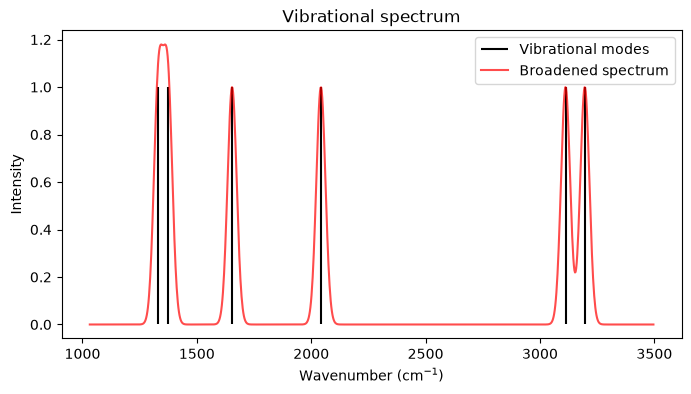

In [5]:
freq = np.asarray(mf_vib.freq) 
vib_mask = freq > 100  # Оставляем только реальные колебания (> 100 см^-1)
freq_vib = freq[vib_mask]
fig, ax = plt.subplots(figsize=(8, 4))
ax.vlines(freq_vib, 0, 1, color='k', label='Vibrational modes')

x = np.linspace(freq_vib.min() - 300, freq_vib.max() + 300, 1000)
sigma = 20  
y = np.exp(-0.5 * ((x[:, None] - freq_vib[None, :]) / sigma)**2).sum(axis=1) # В виде гауссовой функции расширяем спектр
ax.plot(x, y, color='red', alpha=0.7, label='Broadened spectrum')

ax.set_xlabel("Wavenumber (cm$^{-1}$)")
ax.set_ylabel("Intensity")
ax.set_title("Vibrational spectrum")
ax.legend()
plt.show()

Так как почему-то нет модуля для расчета ИК спектра с интенсивностями, пришлось самому расширять спектр и не расчитывать интенсивности

In [6]:
freq_vib_au = freq_vib/ 219474.6313702
thermo.dump_thermo(Mol_opt, thermo.thermo(mf_Freq, freq_vib_au))

temperature 298.1500 [K]
pressure 101325.00 [Pa]
Rotational constants [GHz] 288.90568 40.35799 35.41129
Symmetry number 1
Zero-point energy (ZPE) 0.00068 [Eh]   1780.462 [J/mol]
                           tot       elec      trans        rot        vib
Entropy [J/mol/K]       348.122      0.000    151.175     72.405    124.542
Cv [J/mol/K]             74.562      0.000     12.472     12.472     49.618
Cp [J/mol/K]             82.876      0.000     20.786     12.472     49.618
Internal energy [J/mol]                      3718.434   3718.434  14954.003
Internal energy [Eh]   -113.77125  -113.77977
Enthalpy [J/mol]                             6197.391   3718.434  14954.003
Enthalpy [Eh]          -113.77030
Gibbs free energy [J/mol]                  -38875.527 -17869.227 -22178.058
Gibbs free energy [Eh] -113.80983


In [7]:

def DrawArrow(v, x0, y0, z0, dx, dy, dz, scale):
    v.addArrow({"start": dict(x=x0, y=y0, z=z0),
                "end": dict(x=(x0+dx*scale), y=(y0+dy*scale), z=(z0+dz*scale)),
                "radius": 0.08, "radiusRatio": 2.0, "color": 'green'})

def PySCFmol2XYZstr(m):
    res = str(len(m._atom)) + '\n\n'
    for i in m._atom:
        res += i[0] + '  ' + str(i[1][0]*BOHR) + '  ' + str(i[1][1]*BOHR) + '  ' + str(i[1][2]*BOHR) + '\n'
    return res

natm = Mol_opt.natm
modes_raw = np.asarray(mf_vib.mode)

# меняем вид матрицы (n_modes, natm, 3)
if modes_raw.ndim == 2 and modes_raw.shape[0] == 3 * natm:
    modes_reshaped = modes_raw.T.reshape(-1, natm, 3)
else:
    
    modes_reshaped = modes_raw.reshape(-1, natm, 3)

# моды от 6 до 11, остальные это трансляция и вращение
nmode = 7

print(f"Visualizing Mode {nmode}")
print(f"Frequency: {mf_vib.freq[nmode]:.2f} cm^-1")


vv = py3Dmol.view(width=600, height=400)
vv.addModel(PySCFmol2XYZstr(Mol_opt), 'xyz')
vv.setStyle({"stick": {"radius": 0.15}, "sphere": {"scale": 0.3, "colorscheme": "Jmol"}})

coords_ang = Mol_opt.atom_coords(unit='Angstrom')

for i in range(natm):
    x0, y0, z0 = coords_ang[i]
    dx, dy, dz = modes_reshaped[nmode, i]
    
    # Scale factor to make arrows visible (increase if arrows are too small)
    DrawArrow(vv, x0, y0, z0, dx, dy, dz, scale=2.5)

vv.zoomTo()
vv.show()

Visualizing Mode 7
Frequency: 1373.15 cm^-1


3Dmol.js failed to load for some reason. Please check your browser console for error messages.